In [0]:
catalog = "workspace"
schema = "default"
volume = "water_volume"
folder = "Databricks_Water_Assessment"

base_path = f"/Volumes/{catalog}/{schema}/{volume}/{folder}"

print(base_path)

display(dbutils.fs.ls(base_path))


/Volumes/workspace/default/water_volume/Databricks_Water_Assessment


path,name,size,modificationTime
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/README.md,README.md,2447,1794392899000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/assessment.pdf,assessment.pdf,52715,1794392899000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/assessment_questions.md,assessment_questions.md,7682,1794392899000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/databricks_setup.py,databricks_setup.py,4712,1794392899000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/water_meter_readings.csv,water_meter_readings.csv,11125,1794392900000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/water_reading_changes.csv,water_reading_changes.csv,956,1794392900000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/water_readings_incremental.csv,water_readings_incremental.csv,1391,1794392900000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/water_service_requests.csv,water_service_requests.csv,2662,1794392900000
dbfs:/Volumes/workspace/default/water_volume/Databricks_Water_Assessment/water_zones.json,water_zones.json,2343,1794392900000


In [0]:
%sql
DESCRIBE water_meter_readings_source;

col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


In [0]:
%sql
SELECT COUNT(*) AS total_rows
FROM water_meter_readings_source;

total_rows
157


In [0]:
%sql
SELECT
    reading_id,
    meter_id,
    zone_id,
    reading_time,
    consumption_liters
FROM water_meter_readings_source
WHERE reading_status = 'Valid';

reading_id,meter_id,zone_id,reading_time,consumption_liters
1001,M001,W01,2026-10-01T07:00:00.000Z,2365
1002,M002,W02,2026-10-01T08:10:00.000Z,3545
1003,M003,W03,2026-10-01T09:20:00.000Z,548
1004,M004,W04,2026-10-01T10:00:00.000Z,2871
1006,M006,W06,2026-10-01T12:20:00.000Z,2171
1007,M007,W07,2026-10-01T13:00:00.000Z,4167
1008,M008,W08,2026-10-01T14:10:00.000Z,3621
1009,M009,W09,2026-10-01T15:20:00.000Z,1609
1010,M010,W10,2026-10-01T16:00:00.000Z,1829
1011,M011,W01,2026-10-02T07:10:00.000Z,313


In [0]:
%sql
SELECT *
FROM water_meter_readings_source
WHERE pressure_bar < 2.5
ORDER BY pressure_bar ASC;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


In [0]:
%sql
SELECT *
FROM water_meter_readings_source
WHERE flow_lpm BETWEEN 20 AND 50
  AND source_system IN ('Gateway', 'SmartMeter');

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1014,M014,W04,2026-10-02T10:10:00.000Z,22.4,4.73,0.5,1108,Valid,SmartMeter
1017,M017,W07,2026-10-02T13:10:00.000Z,28.0,3.77,1.08,1318,Valid,SmartMeter
1019,M019,W09,2026-10-02T15:00:00.000Z,23.0,4.34,0.28,1091,Valid,Gateway
1022,M022,W02,2026-10-03T08:00:00.000Z,32.5,3.35,0.6,1706,Suspect,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1047,M017,W07,2026-10-05T13:10:00.000Z,28.8,3.23,0.91,1258,Valid,SmartMeter
1049,M019,W09,2026-10-05T15:00:00.000Z,21.4,2.43,0.47,611,Valid,Gateway
1050,M020,W10,2026-10-05T16:10:00.000Z,37.2,3.91,1.02,2154,Valid,SmartMeter
1056,M026,W06,2026-10-06T12:10:00.000Z,27.2,2.69,0.68,1131,Suspect,SmartMeter


In [0]:
 %sql
 SELECT
    reading_status,
    COUNT(*) AS reading_count
FROM water_meter_readings_source
GROUP BY reading_status
ORDER BY reading_count DESC;

reading_status,reading_count
Valid,137
Suspect,11
Rejected,9


In [0]:
%sql
SELECT
    z.zone_name,
    z.district,
    r.meter_id,
    r.consumption_liters
FROM water_meter_readings_source r
JOIN water_zones z
ON r.zone_id = z.zone_id;

zone_name,district,meter_id,consumption_liters
Old City,Central,M001,2365
Hill View,North,M002,3545
Market District,Central,M003,548
Lake Side,West,M004,2871
University Quarter,East,M005,2656
Industrial Estate,South,M006,2171
Garden Colony,North,M007,4167
Transit Hub,East,M008,3621
Riverfront,West,M009,1609
South Extension,South,M010,1829


In [0]:
%sql
SELECT r.*
FROM water_meter_readings_source r
LEFT JOIN water_zones z
ON r.zone_id = z.zone_id
WHERE z.zone_id IS NULL;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1154,M999,W99,2026-10-16T11:00:00.000Z,24.5,3.0,0.45,1150,Valid,FieldApp
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
%sql
SELECT
    z.zone_id,
    z.zone_name,
    z.district
FROM water_zones z
LEFT JOIN water_meter_readings_source r
ON z.zone_id = r.zone_id
WHERE r.zone_id IS NULL;

zone_id,zone_name,district
W11,New Development,West


In [0]:
%sql
SELECT
    z.zone_name,
    SUM(r.consumption_liters) AS total_consumption,
    ROUND(AVG(r.pressure_bar), 2) AS avg_pressure,
    COUNT(*) AS reading_count
FROM water_meter_readings_source r
JOIN water_zones z
ON r.zone_id = z.zone_id
WHERE r.reading_status = 'Valid'
  AND r.consumption_liters > 0
GROUP BY z.zone_name
ORDER BY total_consumption DESC;

zone_name,total_consumption,avg_pressure,reading_count
Market District,35665,3.02,13
Transit Hub,33689,2.87,14
University Quarter,28717,3.63,14
South Extension,27808,3.72,14
Garden Colony,25104,3.57,13
Hill View,24120,3.31,13
Old City,23107,3.42,13
Riverfront,20894,3.55,13
Lake Side,20781,3.24,14
Industrial Estate,20212,3.16,13


In [0]:
%sql
SELECT
    district,
    meter_id,
    total_consumption,

    RANK() OVER (
        PARTITION BY district
        ORDER BY total_consumption DESC
    ) AS district_rank

FROM (

    SELECT
        z.district,
        r.meter_id,
        SUM(r.consumption_liters) AS total_consumption

    FROM water_meter_readings_source r
    JOIN water_zones z
    ON r.zone_id = z.zone_id

    WHERE r.reading_status = 'Valid'
      AND r.consumption_liters > 0

    GROUP BY
        z.district,
        r.meter_id

) t;

district,meter_id,total_consumption,district_rank
Central,M023,17814,1
Central,M001,11416,2
Central,M003,10447,3
Central,M013,7404,4
Central,M021,7395,5
Central,M011,4296,6
East,M008,14095,1
East,M018,10660,2
East,M025,10536,3
East,M015,9807,4


In [0]:
readings_df = spark.table("water_meter_readings_source")
zones_df = spark.table("water_zones")

readings_df.printSchema()
zones_df.printSchema()


root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)



In [0]:
from pyspark.sql.functions import col

high_flow_df = (
    readings_df
    .select(
        "reading_id",
        "meter_id",
        "zone_id",
        "flow_lpm",
        "reading_status"
    )
    .filter(
        (col("reading_status") == "Valid") &
        (col("flow_lpm") >= 60)
    )
    .orderBy(col("flow_lpm").desc())
)

high_flow_df.show()

+----------+--------+-------+--------+--------------+
|reading_id|meter_id|zone_id|flow_lpm|reading_status|
+----------+--------+-------+--------+--------------+
|      1110|    M020|    W10|    84.0|         Valid|
|      1083|    M023|    W03|    83.9|         Valid|
|      1106|    M016|    W06|    83.9|         Valid|
|      1010|    M010|    W10|    81.3|         Valid|
|      1078|    M018|    W08|    80.7|         Valid|
|      1013|    M013|    W03|    80.7|         Valid|
|      1093|    M003|    W03|    80.4|         Valid|
|      1031|    M001|    W01|    80.1|         Valid|
|      1123|    M003|    W03|    79.7|         Valid|
|      1044|    M014|    W04|    79.3|         Valid|
|      1117|    M027|    W07|    79.1|         Valid|
|      1026|    M026|    W06|    79.1|         Valid|
|      1040|    M010|    W10|    78.9|         Valid|
|      1088|    M028|    W08|    78.9|         Valid|
|      1135|    M015|    W05|    78.2|         Valid|
|      1077|    M017|    W07

In [0]:
from pyspark.sql.functions import when

flow_df = readings_df.withColumn(
    "flow_category",
    when(col("flow_lpm").isNull(), "Unknown")
    .when(col("flow_lpm") >= 60, "High")
    .when(
        (col("flow_lpm") >= 30) &
        (col("flow_lpm") < 60),
        "Medium"
    )
    .otherwise("Low")
)

flow_df.select(
    "reading_id",
    "flow_lpm",
    "flow_category"
).show()

+----------+--------+-------------+
|reading_id|flow_lpm|flow_category|
+----------+--------+-------------+
|      1001|    39.1|       Medium|
|      1002|    59.9|       Medium|
|      1003|    25.7|          Low|
|      1004|    56.7|       Medium|
|      1005|    61.8|         High|
|      1006|    35.8|       Medium|
|      1007|    65.0|         High|
|      1008|    70.3|         High|
|      1009|    30.8|       Medium|
|      1010|    81.3|         High|
|      1011|    13.0|          Low|
|      1012|    36.3|       Medium|
|      1013|    80.7|         High|
|      1014|    22.4|          Low|
|      1015|    30.9|       Medium|
|      1016|    12.9|          Low|
|      1017|    28.0|          Low|
|      1018|    70.5|         High|
|      1019|    23.0|          Low|
|      1020|    67.7|         High|
+----------+--------+-------------+
only showing top 20 rows


In [0]:
import pyspark.sql.functions as F

zone_flow_df = (
    readings_df.alias("r")
    .join(
        zones_df.alias("z"),
        col("r.zone_id") == col("z.zone_id"),
        "inner"
    )
)

avg_flow_df = (
    zone_flow_df
    .groupBy("zone_type")
    .agg(
        F.avg("flow_lpm").alias("avg_flow_lpm")
    )
    .orderBy("avg_flow_lpm", ascending=False)
)

avg_flow_df.show()

+-------------+------------------+
|    zone_type|      avg_flow_lpm|
+-------------+------------------+
|   Commercial| 56.10000000000001|
|Institutional|          49.33125|
|  Residential|45.155737704918025|
|   Industrial| 43.14374999999999|
|        Mixed|         38.165625|
+-------------+------------------+



In [0]:
top_zones_df = (
    readings_df
    .filter(
        (col("reading_status") == "Valid") &
        (col("consumption_liters") > 0)
    )
    .groupBy("zone_id")
    .agg(
        F.sum("consumption_liters")
         .alias("total_consumption")
    )
    .orderBy(
        col("total_consumption").desc()
    )
    .limit(3)
)

top_zones_df.show()


+-------+-----------------+
|zone_id|total_consumption|
+-------+-----------------+
|    W03|            35665|
|    W08|            33689|
|    W05|            28717|
+-------+-----------------+



In [0]:
top_zones_named_df = (
    readings_df
    .filter(
        (col("reading_status") == "Valid") &
        (col("consumption_liters") > 0)
    )
    .groupBy("zone_id")
    .agg(
        F.sum("consumption_liters")
         .alias("total_consumption")
    )
    .join(zones_df, "zone_id")
    .select(
        "zone_id",
        "zone_name",
        "district",
        "total_consumption"
    )
    .orderBy(
        col("total_consumption").desc()
    )
    .limit(3)
)

top_zones_named_df.show(truncate=False)

+-------+------------------+--------+-----------------+
|zone_id|zone_name         |district|total_consumption|
+-------+------------------+--------+-----------------+
|W03    |Market District   |Central |35665            |
|W08    |Transit Hub       |East    |33689            |
|W05    |University Quarter|East    |28717            |
+-------+------------------+--------+-----------------+



In [0]:
from pyspark.sql.functions import col, count

duplicate_ids = (
    readings_df
    .groupBy("reading_id")
    .agg(count("*").alias("cnt"))
    .filter(col("cnt") > 1)
    .select("reading_id")
)

duplicate_rows = (
    readings_df
    .join(duplicate_ids, "reading_id", "inner")
    .orderBy("reading_id")
)

duplicate_rows.show(truncate=False)


+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1044      |M014    |W04    |2026-10-05 10:10:00|79.3    |1.95        |1.23         |2661              |Valid         |SmartMeter   |
|1044      |M014    |W04    |2026-10-16 13:00:00|36.0    |3.2         |0.8          |1300              |Valid         |Gateway      |
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+



In [0]:
from pyspark.sql.functions import col

missing_df = readings_df.filter(
    col("pressure_bar").isNull() |
    col("source_system").isNull()
)

missing_df.show(truncate=False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1153      |M020    |W10    |2026-10-16 10:00:00|31.4    |NULL        |0.71         |1020              |Valid         |Gateway      |
|1155      |M006    |W06    |2026-10-16 12:00:00|44.0    |2.9         |2.95         |1560              |Suspect       |NULL         |
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+



In [0]:
invalid_df = readings_df.filter(
    (col("flow_lpm") < 0) |
    (col("consumption_liters") <= 0) |
    col("zone_id").isNull()
)

invalid_df.show(truncate=False)

+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|reading_id|meter_id|zone_id|reading_time       |flow_lpm|pressure_bar|chlorine_mg_l|consumption_liters|reading_status|source_system|
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+
|1151      |M004    |W04    |2026-10-16 08:00:00|-12.5   |2.8         |0.62         |500               |Suspect       |Gateway      |
|1152      |M015    |W05    |2026-10-16 09:00:00|22.0    |2.1         |0.5          |0                 |Valid         |SmartMeter   |
|1156      |M012    |NULL   |2026-10-16 12:30:00|28.0    |3.1         |0.52         |870               |Valid         |Gateway      |
+----------+--------+-------+-------------------+--------+------------+-------------+------------------+--------------+-------------+



In [0]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number

window_spec = Window.partitionBy("reading_id") \
                    .orderBy(col("reading_time").desc())

clean_df = (
    readings_df
    .filter(
        (col("reading_status") == "Valid") &
        (col("consumption_liters") > 0) &
        (col("flow_lpm") >= 0) &
        col("zone_id").isNotNull()
    )
    .withColumn(
        "rn",
        row_number().over(window_spec)
    )
    .filter(col("rn") == 1)
    .drop("rn")
)

clean_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("water_readings_clean")

In [0]:
requests_df = spark.table("water_service_requests")
high_priority_zones = (
    requests_df
    .filter(col("priority") == "High")
    .select("zone_id")
    .distinct()
)

pressure_comparison = (
    readings_df
    .join(high_priority_zones, "zone_id")
    .groupBy("zone_id")
    .agg(
        F.avg("pressure_bar").alias("avg_pressure"),
        F.count("*").alias("reading_count")
    )
    .orderBy("avg_pressure")
)

pressure_comparison.show(truncate=False)

+-------+------------------+-------------+
|zone_id|avg_pressure      |reading_count|
+-------+------------------+-------------+
|W08    |2.92              |15           |
|W03    |3.178             |15           |
|W06    |3.2250000000000005|16           |
|W04    |3.2829411764705885|17           |
|W02    |3.3573333333333335|15           |
|W07    |3.3706666666666667|15           |
|W01    |3.437333333333333 |15           |
|W05    |3.5               |16           |
|W09    |3.6040000000000005|15           |
|W10    |3.7079999999999997|16           |
+-------+------------------+-------------+



Q19:
Rule: When multiple records share the same reading_id, retain only the most recent record based on reading_time (row_number() = 1 ordered by descending timestamp). This ensures one unique reading per reading_id in water_readings_clean.

In [0]:
%sql
CREATE OR REPLACE TABLE water_readings_work_copy
AS
SELECT *
FROM water_meter_readings_work;

num_affected_rows,num_inserted_rows


In [0]:
%sql DESCRIBE water_readings_work_copy;

col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


In [0]:
%sql
INSERT INTO water_readings_work_copy
VALUES
(
  9001,
  'MTR901',
  'Z01',
  CURRENT_TIMESTAMP(),
  250.5,
  42.0,
  3.2,
  30,
  'Valid',
  'Gateway'
),
(
  9002,
  'MTR902',
  'Z02',
  CURRENT_TIMESTAMP(),
  315.8,
  55.0,
  3.5,
  25,
  'Valid',
  'SmartMeter'
);

num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
SELECT *
FROM water_readings_work_copy
WHERE reading_id IN (9001,9002);

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
9001,MTR901,Z01,2026-11-11T11:39:15.954Z,250.5,42.0,3.2,30,Valid,Gateway
9002,MTR902,Z02,2026-11-11T11:39:15.954Z,315.8,55.0,3.5,25,Valid,SmartMeter


In [0]:
%sql
SELECT *
FROM water_readings_work_copy
WHERE reading_status = 'Suspect'
LIMIT 1;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter


In [0]:
%sql
UPDATE water_readings_work_copy
SET reading_status = 'Rejected'
WHERE reading_id = 105;

num_affected_rows
0


In [0]:
%sql
SELECT *
FROM water_readings_work_copy
WHERE reading_id = 105;


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system


In [0]:
%sql
SELECT COUNT(*) AS rejected_before
FROM water_readings_work_copy
WHERE reading_status = 'Rejected';

rejected_before
9


In [0]:
%sql
DELETE FROM water_readings_work_copy
WHERE reading_status = 'Rejected';

num_affected_rows
9


In [0]:
%sql
SELECT COUNT(*) AS rejected_after
FROM water_readings_work_copy
WHERE reading_status = 'Rejected';

rejected_after
0


In [0]:
from pyspark.sql import functions as F

readings_df = spark.table("water_readings_clean")

zone_summary_df = (
    readings_df
    .filter(
        (F.col("reading_status") == "Valid") &
        (F.col("consumption_liters") > 0)
    )
    .groupBy("zone_id")
    .agg(
        F.sum("consumption_liters").alias("total_consumption"),
        F.avg("pressure_bar").alias("avg_pressure"),
        F.count("*").alias("reading_count")
    )
)


In [0]:
zone_summary_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("zone_consumption_summary")

In [0]:
%sql
SELECT c.reading_id
FROM water_reading_changes c
JOIN water_meter_readings_work w
ON c.reading_id = w.reading_id;

reading_id
1005
1027
1062
1088
1119
1145


In [0]:
%sql
SELECT c.reading_id
FROM water_reading_changes c
LEFT ANTI JOIN water_meter_readings_work w
ON c.reading_id = w.reading_id;

reading_id
1201
1202
1203
1204
1205
1206


In [0]:
%sql
MERGE INTO water_meter_readings_work tgt
USING water_reading_changes src
ON tgt.reading_id = src.reading_id

WHEN MATCHED THEN
UPDATE SET
  tgt.meter_id = src.meter_id,
  tgt.zone_id = src.zone_id,
  tgt.reading_time = src.reading_time,
  tgt.consumption_liters = src.consumption_liters,
  tgt.flow_lpm = src.flow_lpm,
  tgt.pressure_bar = src.pressure_bar,
  tgt.reading_status = src.reading_status,
  tgt.source_system = src.source_system

WHEN NOT MATCHED THEN
INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
12,6,0,6


In [0]:
%sql
SELECT w.*
FROM water_meter_readings_work w
JOIN water_reading_changes c
ON w.reading_id = c.reading_id;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03T13:20:00.000Z,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07T08:10:00.000Z,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09T14:00:00.000Z,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12T15:10:00.000Z,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15T11:00:00.000Z,77.5,3.96,1.29,4908,Valid,FieldApp
1201,M002,W02,2026-10-18T08:00:00.000Z,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18T09:00:00.000Z,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18T10:00:00.000Z,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18T11:00:00.000Z,38.1,2.9,0.6,1550,Valid,FieldApp


In [0]:
%sql
SELECT c.reading_id
FROM water_reading_changes c
LEFT ANTI JOIN water_meter_readings_source s
ON c.reading_id = s.reading_id;


reading_id
1201
1202
1203
1204
1205
1206


In [0]:
%sql
CREATE OR REPLACE TABLE water_meter_readings_work_copy2
AS
SELECT *
FROM water_meter_readings_source;

num_affected_rows,num_inserted_rows


In [0]:
from delta.tables import DeltaTable

target = DeltaTable.forName(
    spark,
    "water_meter_readings_work_copy2"
)

source = spark.table("water_reading_changes")

(
 target.alias("t")
 .merge(
     source.alias("s"),
     "t.reading_id = s.reading_id"
 )
 .whenMatchedUpdateAll()
 .whenNotMatchedInsertAll()
 .execute()
)

DataFrame[num_affected_rows: bigint, num_updated_rows: bigint, num_deleted_rows: bigint, num_inserted_rows: bigint]

In [0]:
%sql
CREATE OR REPLACE TABLE zone_capacity_history
(
    zone_id STRING,
    zone_name STRING,
    capacity INT,
    effective_from DATE,
    effective_to DATE,
    is_current BOOLEAN
)
USING DELTA;

In [0]:
%sql
INSERT INTO zone_capacity_history
SELECT
    zone_id,
    zone_name,
    daily_capacity_liters,
    DATE('2026-01-01') AS effective_from,
    NULL AS effective_to,
    TRUE AS is_current
FROM water_zones;

num_affected_rows,num_inserted_rows
11,11


In [0]:
%sql
UPDATE zone_capacity_history
SET
    effective_to = DATE('2026-10-19'),
    is_current = FALSE
WHERE zone_id IN ('W02','W06')
  AND is_current = TRUE;

num_affected_rows
2


In [0]:
%sql
INSERT INTO zone_capacity_history
VALUES
(
 'W02',
 'Zone W02',
 195000,
 DATE('2026-10-20'),
 NULL,
 TRUE
);

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
INSERT INTO zone_capacity_history
VALUES
(
 'W06',
 'Zone W06',
 305000,
 DATE('2026-10-20'),
 NULL,
 TRUE
);

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,c07b15af-5ee3-474a-a1db-cc0e4ab66283,workspace.default.water_meter_readings_work,null,,2026-11-11T10:32:05.859Z,2026-11-11T11:44:27.000Z,List(),List(),2,8838,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",false


In [0]:
%sql
DESCRIBE HISTORY water_meter_readings_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
1,2026-11-11T11:44:27.000Z,70638158589839,kishorekarthick0803@gmail.com,MERGE,"Map(predicate -> [""(reading_id#16630 = reading_id#16650)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(9135759931621),416fb43d-3cc0-4216-8c28-0551078ad6b5,1111-111947-x9rn7d0x-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 2986, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1102, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1814)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
0,2026-11-11T10:32:08.000Z,70638158589839,kishorekarthick0803@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(9135759931630),f73ea344-5379-4e8a-b466-8f0562babd7c,1111-092752-3iz5fmpx-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5424)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13


In [0]:
%sql
SELECT *
FROM water_meter_readings_work
VERSION AS OF 0
WHERE reading_id = 1005;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter


In [0]:
%sql
SELECT *
FROM water_meter_readings_work
WHERE reading_id = 1005;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp


In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,c07b15af-5ee3-474a-a1db-cc0e4ab66283,workspace.default.water_meter_readings_work,null,,2026-11-11T10:32:05.859Z,2026-11-11T11:44:27.000Z,List(),List(),2,8838,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",false


In [0]:
%sql
OPTIMIZE water_meter_readings_work;

path,metrics
,"List(1, 2, List(5839, 5839, 5839.0, 1, 5839), List(3414, 5424, 4419.0, 2, 8838), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794398291754, 1794398293728, 8, 1, null, List(1, 6), null, 10, 10, 494, 0, null, null, 0)"


In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,c07b15af-5ee3-474a-a1db-cc0e4ab66283,workspace.default.water_meter_readings_work,null,,2026-11-11T10:32:05.859Z,2026-11-11T11:58:14.000Z,List(),List(),1,5839,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


35. Explain VACUUM retention and perform a dry run
Purpose of VACUUM

VACUUM removes obsolete data files that are no longer referenced by the Delta transaction log.

Benefits:
Reduces storage usage
Removes obsolete files
Improves storage management

In [0]:
%sql
SELECT current_catalog(), current_schema();

current_catalog(),current_schema()
workspace,default


In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_work;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,c07b15af-5ee3-474a-a1db-cc0e4ab66283,workspace.default.water_meter_readings_work,null,,2026-11-11T10:32:05.859Z,2026-11-11T11:58:14.000Z,List(),List(),1,5839,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
%sql
CREATE OR REPLACE VIEW vw_valid_water_readings AS
SELECT
    r.reading_id,
    r.meter_id,
    r.zone_id,
    z.zone_name,
    z.district,
    r.reading_time,
    r.consumption_liters,
    r.pressure_bar
FROM water_meter_readings_work r
JOIN water_zones z
ON r.zone_id = z.zone_id
WHERE r.reading_status = 'Valid';

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW temp_low_pressure_readings AS
SELECT *
FROM water_meter_readings_work
WHERE pressure_bar < 2.5;

In [0]:
%sql
CREATE OR REPLACE GLOBAL TEMP VIEW global_high_priority_requests AS
SELECT *
FROM water_service_requests
WHERE priority = 'High';

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-6160779148739654>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', "CREATE OR REPLACE GLOBAL TEMP VIEW global_high_priority_requests AS\nSELECT *\nFROM water_service_requests\nWHERE priority = 'High';\n")

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/lib/dbruntime/sql_magic/sql_magic.py:217, in SqlMagic.sq

In [0]:
readings_df = spark.table("water_meter_readings_work")

In [0]:
parquet_path = "/Volumes/workspace/default/water_volume/parquet_water_readings"

readings_df.write \
    .mode("overwrite") \
    .parquet(parquet_path)

In [0]:
parquet_df = spark.read.parquet(parquet_path)

parquet_df.printSchema()

display(parquet_df)


root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)



reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway
1011,M011,W01,2026-10-02T07:10:00.000Z,13.0,4.39,0.66,313,Valid,SmartMeter


In [0]:
parquet_df.write \
    .format("delta") \
    .mode("overwrite") \
    .saveAsTable("water_meter_readings_delta")

In [0]:
rate_df = (
    spark.readStream
         .format("rate")
         .option("rowsPerSecond", 5)
         .load()
)

rate_df.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- value: long (nullable = true)



In [0]:
from pyspark.sql.functions import *

stream_df = (
    rate_df
    .withColumn(
        "meter_id",
        concat(lit("MTR"), col("value"))
    )
    .withColumn(
        "flow_lpm",
        (col("value") % 100).cast("int")
    )
)

stream_df.printSchema()

root
 |-- timestamp: timestamp (nullable = true)
 |-- value: long (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- flow_lpm: integer (nullable = true)



In [0]:
filtered_df = stream_df.filter(
    col("flow_lpm") > 50
)

In [0]:
category_df = filtered_df.withColumn(
    "flow_category",
    when(col("flow_lpm") >= 80, "High")
    .when(col("flow_lpm") >= 60, "Medium")
    .otherwise("Low")
)

In [0]:
agg_df = (
    category_df
    .groupBy("flow_category")
    .count()
)

In [0]:
query = (
    agg_df.writeStream
          .format("console")
          .outputMode("complete")
          .option(
              "checkpointLocation",
              "/tmp/checkpoints/flow_summary"
          )
          .trigger(availableNow=True)
          .start()
)

query.awaitTermination()

---------------------------------------------------------------------------
UnsupportedOperationException             Traceback (most recent call last)
File <command-6160779148739664>, line 11
      1 query = (
      2     agg_df.writeStream
      3           .format("memory")
      4           .outputMode("complete")
      5           .queryName("flow_summary")
      6           .option(
      7               "checkpointLocation",
      8               "/tmp/checkpoints/flow_summary"
      9           )
     10           .trigger(availableNow=True)
---> 11           .start()
     12 )
     13 query.awaitTermination()

File /databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/streaming/readwriter.py:793, in DataStreamWriter.start(self, path, format, outputMode, partitionBy, queryName, **options)
    784 def start(
    785     self,
    786     path: Optional[str] = None,
   (...)    791     **options: "OptionalPrimitiveType",
    792 ) -> "StreamingQuery":
--> 793     re

In [0]:
query.stop()

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-6160779148739665>, line 1
----> 1 query.stop()

NameError: name 'query' is not defined

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bronze_water_readings
AS
SELECT *
FROM STREAM(water_meter_readings_source);

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE silver_water_readings
AS
SELECT
    reading_id,
    meter_id,
    zone_id,
    reading_time,
    consumption_liters,
    flow_lpm,
    pressure_bar,
    reading_status,
    source_system
FROM STREAM(bronze_water_readings)
WHERE reading_status = 'Valid'
  AND flow_lpm > 0
  AND consumption_liters > 0;

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW gold_zone_summary
AS
SELECT
    zone_id,
    SUM(consumption_liters) AS total_consumption,
    ROUND(AVG(pressure_bar),2) AS avg_pressure,
    COUNT(*) AS reading_count
FROM silver_water_readings
GROUP BY zone_id;

result
The operation was successfully executed.


In [0]:
%sql
SELECT *
FROM bronze_water_readings
LIMIT 20;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway


In [0]:
%sql
SELECT *
FROM silver_water_readings
LIMIT 20;

reading_id,meter_id,zone_id,reading_time,consumption_liters,flow_lpm,pressure_bar,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,2365,39.1,3.56,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,3545,59.9,4.6,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,548,25.7,2.22,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,2871,56.7,2.84,Valid,Gateway
1006,M006,W06,2026-10-01T12:20:00.000Z,2171,35.8,2.52,Valid,FieldApp
1007,M007,W07,2026-10-01T13:00:00.000Z,4167,65.0,3.19,Valid,Gateway
1008,M008,W08,2026-10-01T14:10:00.000Z,3621,70.3,3.39,Valid,SmartMeter
1009,M009,W09,2026-10-01T15:20:00.000Z,1609,30.8,4.57,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,1829,81.3,2.38,Valid,Gateway
1011,M011,W01,2026-10-02T07:10:00.000Z,313,13.0,4.39,Valid,SmartMeter


In [0]:
%sql
SELECT *
FROM gold_zone_summary
ORDER BY total_consumption DESC;

zone_id,total_consumption,avg_pressure,reading_count
W03,35665,3.02,13
W08,33689,2.87,14
W05,28717,3.63,14
W10,27808,3.72,14
W07,25104,3.57,13
W02,24120,3.31,13
W01,23107,3.42,13
W09,20894,3.55,13
W04,20781,3.24,14
W06,20212,3.16,13


In [0]:
from pyspark import pipelines as dp
from pyspark.sql.functions import *

@dp.table(
    name="bronze_water_readings_py"
)
def bronze_water_readings_py():

    return spark.readStream.table(
        "water_meter_readings_source"
    )

@dp.table(
    name="silver_water_readings_py"
)
def silver_water_readings_py():

    df = spark.readStream.table(
        "bronze_water_readings_py"
    )

    return (
        df.filter(
            (col("reading_status") == "Valid") &
            (col("flow_lpm") > 0) &
            (col("consumption_liters") > 0)
        )
    )

@dp.materialized_view(
    name="gold_zone_summary_py"
)
def gold_zone_summary_py():

    return (
        spark.read.table(
            "silver_water_readings_py"
        )
        .groupBy("zone_id")
        .agg(
            sum("consumption_liters")
                .alias("total_consumption"),

            avg("pressure_bar")
                .alias("avg_pressure"),

            count("*")
                .alias("reading_count")
        )
    )

In [0]:
%sql
SELECT *
FROM bronze_water_readings_py;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01T08:10:00.000Z,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01T10:00:00.000Z,56.7,2.84,1.1,2871,Valid,Gateway
1005,M005,W05,2026-10-01T11:10:00.000Z,61.8,3.04,0.43,2656,Suspect,SmartMeter
1006,M006,W06,2026-10-01T12:20:00.000Z,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01T13:00:00.000Z,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01T14:10:00.000Z,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01T15:20:00.000Z,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway


In [0]:
%sql
SELECT *
FROM water_readings_incremental_staging;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1161,M003,W03,2026-10-19T07:00:00.000Z,17.0,2.1,0.35,700,Suspect,Gateway
1162,M005,W05,2026-10-19T08:00:00.000Z,19.3,2.38,0.48,790,Valid,SmartMeter
1163,M007,W07,2026-10-19T09:00:00.000Z,21.6,2.66,0.61,880,Valid,Gateway
1164,M009,W09,2026-10-19T10:00:00.000Z,23.9,2.94,0.74,970,Valid,SmartMeter
1165,M011,W01,2026-10-19T11:00:00.000Z,26.2,3.22,0.87,1060,Valid,Gateway
1166,M013,W03,2026-10-19T12:00:00.000Z,28.5,3.5,0.35,1150,Valid,SmartMeter
1167,M015,W05,2026-10-20T07:00:00.000Z,30.8,2.1,0.48,1240,Valid,Gateway
1168,M017,W07,2026-10-20T08:00:00.000Z,33.1,2.38,0.61,1330,Suspect,SmartMeter
1169,M019,W09,2026-10-20T09:00:00.000Z,35.4,2.66,0.74,1420,Valid,Gateway
1170,M021,W01,2026-10-20T10:00:00.000Z,37.7,2.94,0.87,1510,Valid,SmartMeter


In [0]:
%sql
SELECT COUNT(*) AS staging_count
FROM water_readings_incremental_staging;

staging_count
18


In [0]:
%sql
INSERT INTO water_meter_readings_source
SELECT *
FROM water_readings_incremental_staging;

num_affected_rows,num_inserted_rows
18,18


In [0]:
%sql
SELECT COUNT(*) AS source_count
FROM water_readings_incremental_staging;

source_count
18


In [0]:
%sql
SELECT COUNT(*)
FROM bronze_water_readings;

COUNT(*)
157


In [0]:
%sql
SELECT COUNT(*)
FROM silver_water_readings;

COUNT(*)
136


In [0]:
%sql
SELECT *
FROM gold_zone_summary ORDER BY total_consumption DESC;

zone_id,total_consumption,avg_pressure,reading_count
W03,35665,3.02,13
W08,33689,2.87,14
W05,28717,3.63,14
W10,27808,3.72,14
W07,25104,3.57,13
W02,24120,3.31,13
W01,23107,3.42,13
W09,20894,3.55,13
W04,20781,3.24,14
W06,20212,3.16,13


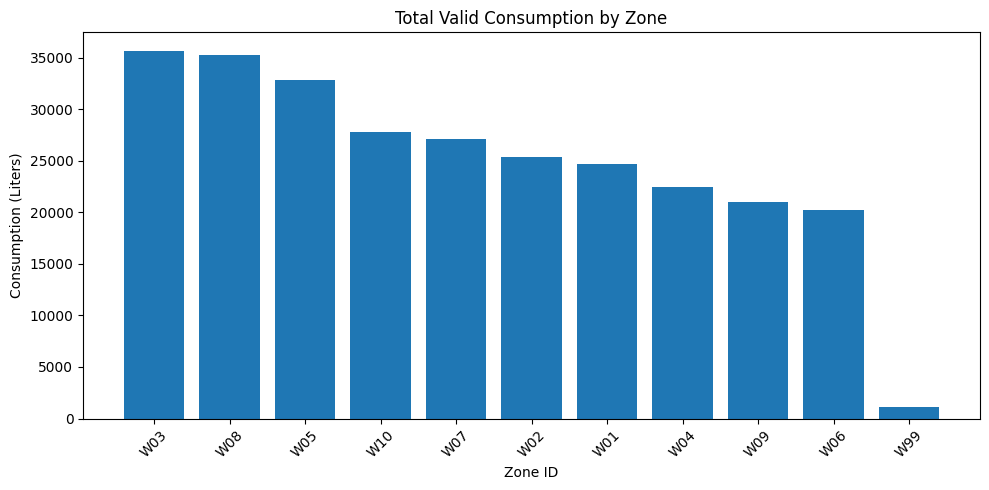

In [0]:
import matplotlib.pyplot as plt

zone_df = spark.sql("""
SELECT
    zone_id,
    SUM(consumption_liters) AS total_consumption
FROM water_meter_readings_work
WHERE reading_status = 'Valid'
AND consumption_liters > 0
AND zone_id IS NOT NULL
GROUP BY zone_id
ORDER BY total_consumption DESC
""").toPandas()

plt.figure(figsize=(10,5))
plt.bar(zone_df["zone_id"], zone_df["total_consumption"])
plt.title("Total Valid Consumption by Zone")
plt.xlabel("Zone ID")
plt.ylabel("Consumption (Liters)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

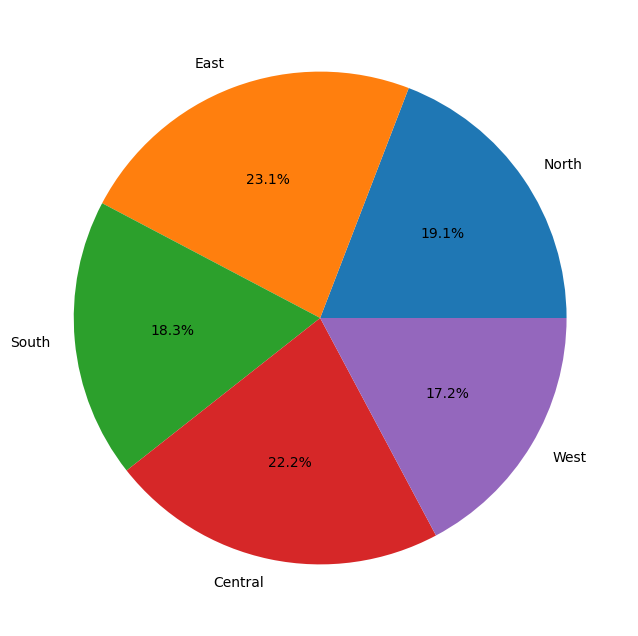

In [0]:
district_df = spark.sql("""
SELECT
    z.district,
    SUM(r.consumption_liters) total_consumption
FROM water_meter_readings_work r
JOIN water_zones z
ON r.zone_id=z.zone_id
GROUP BY z.district
""").toPandas()

district_df = district_df.dropna()

plt.figure(figsize=(8,8))
plt.pie(
    district_df["total_consumption"],
    labels=district_df["district"].astype(str),
    autopct="%1.1f%%"
)

plt.show()

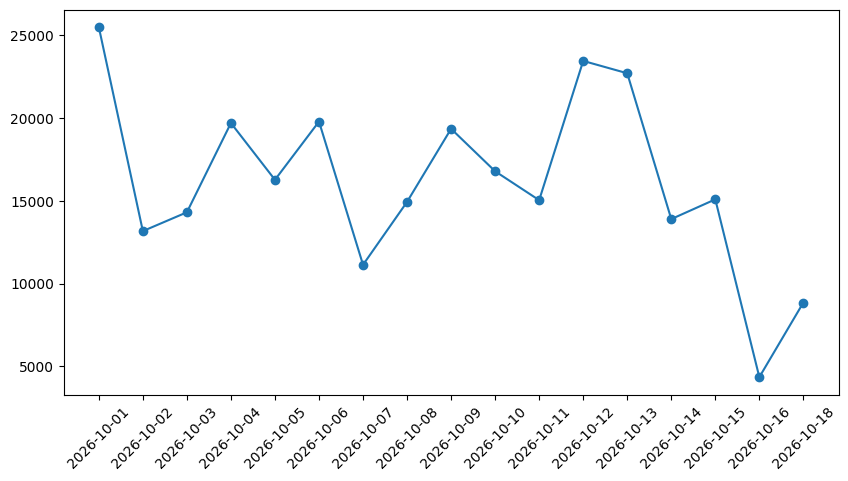

In [0]:
daily_df = spark.sql("""
SELECT
DATE(reading_time) reading_date,
SUM(consumption_liters) daily_consumption
FROM water_meter_readings_work
WHERE reading_status='Valid'
GROUP BY DATE(reading_time)
ORDER BY reading_date
""").toPandas()

daily_df = daily_df.dropna()

daily_df["reading_date"] = daily_df["reading_date"].astype(str)

plt.figure(figsize=(10,5))
plt.plot(
    daily_df["reading_date"],
    daily_df["daily_consumption"],
    marker="o"
)

plt.xticks(rotation=45)
plt.show()

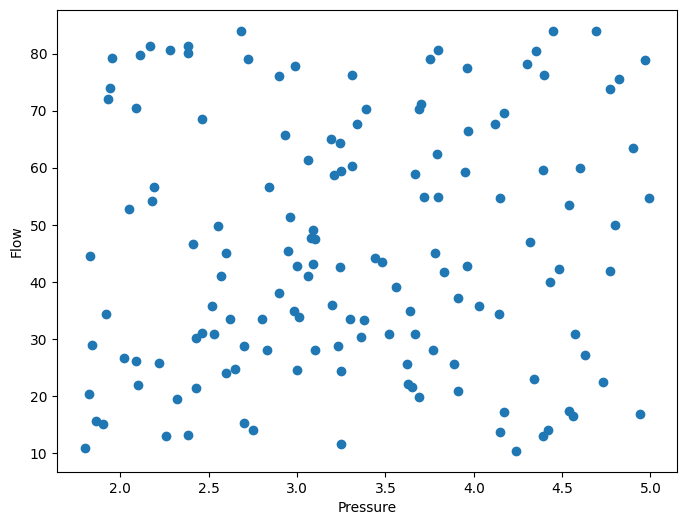

In [0]:
scatter_df = spark.sql("""
SELECT
pressure_bar,
flow_lpm
FROM water_meter_readings_work
WHERE reading_status='Valid'
""").toPandas()

scatter_df = scatter_df.dropna()

plt.figure(figsize=(8,6))

plt.scatter(
    scatter_df["pressure_bar"],
    scatter_df["flow_lpm"]
)

plt.xlabel("Pressure")
plt.ylabel("Flow")
plt.show()

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bronze_water_readings
AS
SELECT *
FROM STREAM(water_meter_readings_source);


message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE silver_water_readings
AS
SELECT
    reading_id,
    meter_id,
    zone_id,
    reading_time,
    consumption_liters,
    flow_lpm,
    pressure_bar,
    source_system,
    reading_status
FROM STREAM(bronze_water_readings)
WHERE reading_status = 'Valid'
  AND flow_lpm > 0
  AND consumption_liters > 0;

message
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW gold_zone_summary
AS
SELECT
    z.zone_id,
    z.zone_name,
    z.district,
    SUM(s.consumption_liters) AS total_consumption,
    AVG(s.pressure_bar) AS avg_pressure,
    COUNT(*) AS reading_count
FROM silver_water_readings s
JOIN water_zones z
ON s.zone_id = z.zone_id
GROUP BY
    z.zone_id,
    z.zone_name,
    z.district;

result
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW gold_district_summary
AS
SELECT
    district,
    SUM(total_consumption) AS district_consumption,
    AVG(avg_pressure) AS district_pressure
FROM gold_zone_summary
GROUP BY district;

result
The operation was successfully executed.


In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW water_quality_alerts
AS
SELECT
    zone_id,
    AVG(pressure_bar) AS avg_pressure,
    AVG(flow_lpm) AS avg_flow,
    CASE
        WHEN AVG(pressure_bar) < 2.5 THEN 'Low Pressure'
        ELSE 'Normal'
    END AS pressure_status
FROM silver_water_readings
GROUP BY zone_id;

result
The operation was successfully executed.


In [0]:
%sql
MERGE INTO water_meter_readings_work tgt
USING water_reading_changes src
ON tgt.reading_id = src.reading_id

WHEN MATCHED THEN
UPDATE SET *

WHEN NOT MATCHED THEN
INSERT *;

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
12,12,0,0


In [0]:
%sql
DESCRIBE HISTORY water_meter_readings_work;

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
3,2026-11-11T15:12:44.000Z,70638158589839,kishorekarthick0803@gmail.com,MERGE,"Map(predicate -> [""(reading_id#19541 = reading_id#19551)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> false, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(9135759931621),a86577bf-87af-49e5-a329-4c166b90adef,1111-150756-ksilemjc-v2n,2,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 12, executionTimeMs -> 4468, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 0, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 2299, numTargetRowsUpdated -> 12, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 2066)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
2,2026-11-11T11:58:14.000Z,70638158589839,kishorekarthick0803@gmail.com,OPTIMIZE,"Map(predicate -> [], auto -> false, clusterBy -> [], zOrderBy -> [], batchId -> 0)",null,List(9135759931621),c50a3436-f654-425b-9648-4c5bdc43c286,1111-111947-x9rn7d0x-v2n,1,SnapshotIsolation,false,"Map(numRemovedFiles -> 2, numRemovedBytes -> 8838, p25FileSize -> 5839, numDeletionVectorsRemoved -> 1, minFileSize -> 5839, numAddedFiles -> 1, maxFileSize -> 5839, p75FileSize -> 5839, p50FileSize -> 5839, numAddedBytes -> 5839)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
1,2026-11-11T11:44:27.000Z,70638158589839,kishorekarthick0803@gmail.com,MERGE,"Map(predicate -> [""(reading_id#16630 = reading_id#16650)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(9135759931621),416fb43d-3cc0-4216-8c28-0551078ad6b5,1111-111947-x9rn7d0x-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 2986, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1102, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1814)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
0,2026-11-11T10:32:08.000Z,70638158589839,kishorekarthick0803@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(9135759931630),f73ea344-5379-4e8a-b466-8f0562babd7c,1111-092752-3iz5fmpx-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5424)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13


In [0]:
%sql
SELECT *
FROM water_meter_readings_work
VERSION AS OF 3
WHERE reading_id = 1005;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp


In [0]:
%sql
SELECT *
FROM water_meter_readings_work
WHERE reading_id = 1005;


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01T11:10:00.000Z,64.3,3.24,0.43,2776,Valid,FieldApp


In [0]:
%sql
SELECT *
FROM water_readings_incremental_staging;

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1161,M003,W03,2026-10-19T07:00:00.000Z,17.0,2.1,0.35,700,Suspect,Gateway
1162,M005,W05,2026-10-19T08:00:00.000Z,19.3,2.38,0.48,790,Valid,SmartMeter
1163,M007,W07,2026-10-19T09:00:00.000Z,21.6,2.66,0.61,880,Valid,Gateway
1164,M009,W09,2026-10-19T10:00:00.000Z,23.9,2.94,0.74,970,Valid,SmartMeter
1165,M011,W01,2026-10-19T11:00:00.000Z,26.2,3.22,0.87,1060,Valid,Gateway
1166,M013,W03,2026-10-19T12:00:00.000Z,28.5,3.5,0.35,1150,Valid,SmartMeter
1167,M015,W05,2026-10-20T07:00:00.000Z,30.8,2.1,0.48,1240,Valid,Gateway
1168,M017,W07,2026-10-20T08:00:00.000Z,33.1,2.38,0.61,1330,Suspect,SmartMeter
1169,M019,W09,2026-10-20T09:00:00.000Z,35.4,2.66,0.74,1420,Valid,Gateway
1170,M021,W01,2026-10-20T10:00:00.000Z,37.7,2.94,0.87,1510,Valid,SmartMeter


In [0]:
%sql
INSERT INTO water_meter_readings_source
SELECT *
FROM water_readings_incremental_staging;

num_affected_rows,num_inserted_rows
18,18


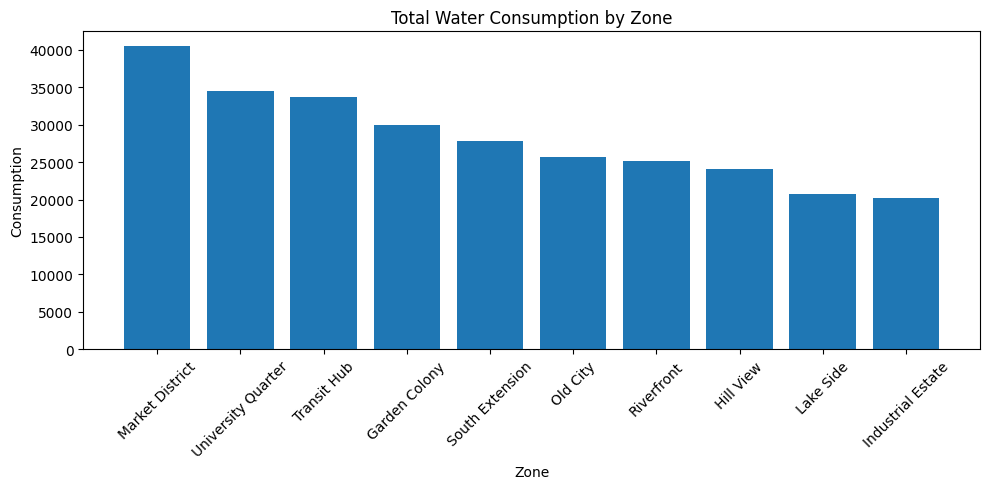

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    zone_name,
    total_consumption
FROM gold_zone_summary
ORDER BY total_consumption DESC
""").toPandas()

df = df.dropna()

plt.figure(figsize=(10,5))
plt.bar(df["zone_name"], df["total_consumption"])
plt.xticks(rotation=45)
plt.title("Total Water Consumption by Zone")
plt.xlabel("Zone")
plt.ylabel("Consumption")
plt.tight_layout()
plt.show()

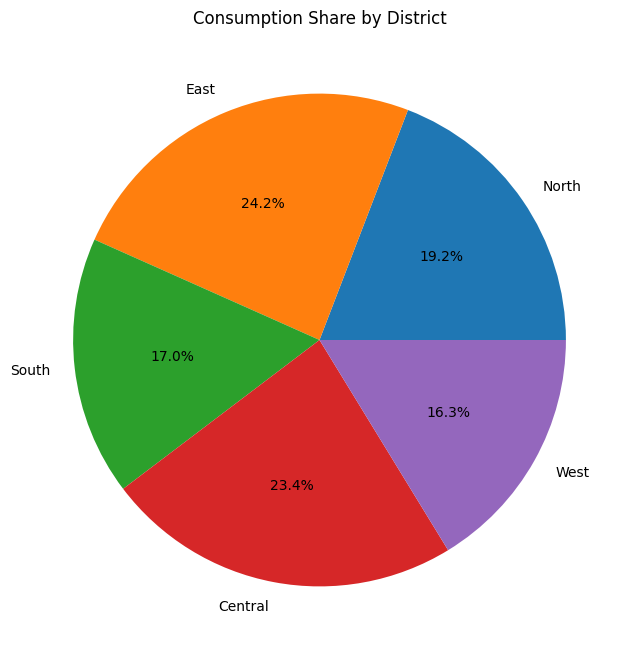

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    district,
    district_consumption
FROM gold_district_summary
""").toPandas()

df = df.dropna()

plt.figure(figsize=(8,8))

plt.pie(
    df["district_consumption"],
    labels=df["district"].astype(str),
    autopct="%1.1f%%"
)

plt.title("Consumption Share by District")
plt.show()

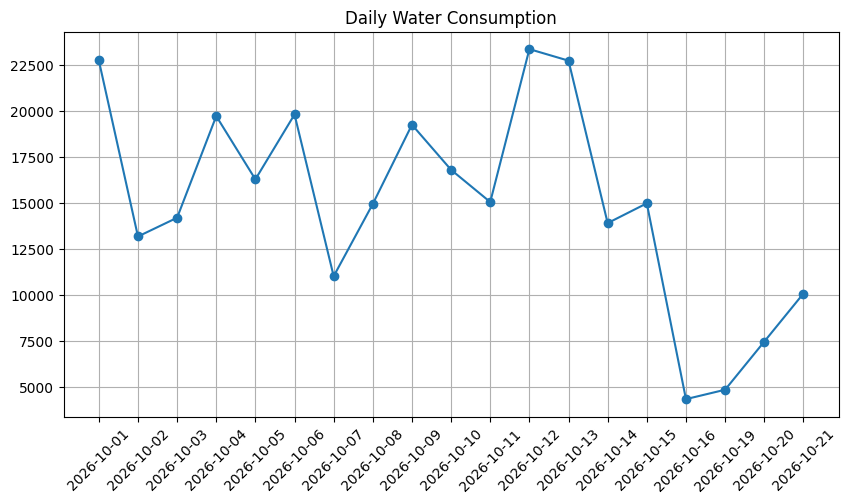

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    DATE(reading_time) AS reading_date,
    SUM(consumption_liters) AS daily_consumption
FROM silver_water_readings
GROUP BY DATE(reading_time)
ORDER BY reading_date
""").toPandas()

df = df.dropna()

plt.figure(figsize=(10,5))

plt.plot(
    df["reading_date"].astype(str),
    df["daily_consumption"],
    marker="o"
)

plt.xticks(rotation=45)
plt.title("Daily Water Consumption")
plt.grid(True)

plt.show()

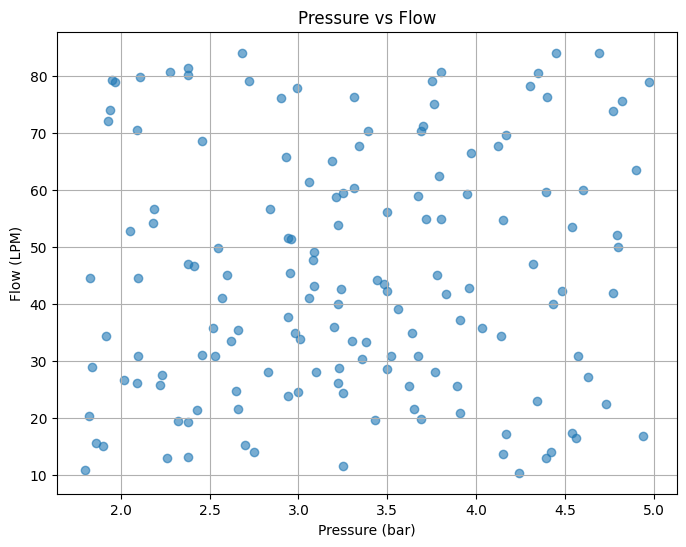

In [0]:
import matplotlib.pyplot as plt

df = spark.sql("""
SELECT
    pressure_bar,
    flow_lpm
FROM silver_water_readings
WHERE pressure_bar IS NOT NULL
  AND flow_lpm IS NOT NULL
""").toPandas()

df = df.dropna()

plt.figure(figsize=(8,6))

plt.scatter(
    df["pressure_bar"],
    df["flow_lpm"],
    alpha=0.6
)

plt.xlabel("Pressure (bar)")
plt.ylabel("Flow (LPM)")
plt.title("Pressure vs Flow")
plt.grid(True)

plt.show()